# Random forest results

Compares the Python random forest (`random_forest.py`) across five predictor
sets:

| Feature set | Inputs |
|---|---|
| `score` | score difference, total points, next server, fifth set |
| `score_skills` | score + 38 cumulative skill counts |
| `score_rates` | score + skill rate differences + attack attempts |
| `skills` | the 38 skill counts only |
| `rates` | skill rate differences + attack attempts only (no sideout %, which is points won) |

Everything uses **cross-validation predictions only** (training seasons); test
predictions are not touched. Lower Brier score is better; each set counts
equally.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from evaluation import KEYS, load_model_data

MODEL = "sklearn_rf"

live = load_model_data()
meta = live.meta.assign(score_difference=live.x_score["score_difference"])
pred = pd.concat(pd.read_csv(f) for f in sorted(Path("predictions").glob(f"{MODEL}__*.csv")))
pred = pred[pred["split"] == "cv"].merge(meta, on=KEYS)
pred["brier"] = (pred["win_probability"] - pred["home_set_win"]) ** 2
pred["feature_set"].value_counts()

feature_set
rates           12902
score           12902
score_rates     12902
score_skills    12902
skills          12902
Name: count, dtype: int64

## Scoring

Each version's Brier score is averaged within each set, then across sets. Each
version is compared with the **score-only forest**; the interval comes from
resampling whole matches with replacement (the same matches for both
versions, so the comparison is paired).

In [2]:
REFERENCE = "score"

def score(rallies, reps=2000, seed=4640):
    """Set-averaged Brier per feature set, plus a paired match-bootstrap
    interval for the difference from the score-only forest."""
    per_set = (rallies.groupby(["feature_set", "match_id", "set_number"])["brier"]
               .mean().reset_index())
    by_match = per_set.groupby(["feature_set", "match_id"])["brier"].agg(["sum", "count"])
    sums = by_match["sum"].unstack("feature_set")
    sets = by_match["count"].unstack("feature_set")[REFERENCE]
    rng = np.random.default_rng(seed)
    draws = rng.multinomial(len(sums), np.full(len(sums), 1 / len(sums)), size=reps)
    boot = pd.DataFrame((draws @ sums.to_numpy()) / (draws @ sets.to_numpy())[:, None],
                        columns=sums.columns)
    diff = boot.sub(boot[REFERENCE], axis=0)
    return pd.DataFrame({
        "brier": sums.sum() / sets.sum(),
        "sets": sets.sum(),
        "diff": diff.mean(),
        "diff_low": diff.quantile(0.025),
        "diff_high": diff.quantile(0.975),
    })

overall = score(pred)
overall.sort_values("brier").round(4)

,brier,sets,diff,diff_low,diff_high
feature_set,,,,,
score,0.1567,298,0.0000,0.0000,0.0000
score_skills,0.1568,298,0.0001,-0.0022,0.0025
score_rates,0.1578,298,0.0011,-0.0009,0.0033
skills,0.1777,298,0.0209,0.0137,0.0281
rates,0.1792,298,0.0224,0.0133,0.0322


## Plot style

Colour shows which skill information a version uses (counts or rates); a
filled marker means the score inputs are included, a hollow one means skills
alone. The score-only forest is the reference.

In [3]:
VERSIONS = {  # feature set -> (label, colour, includes score inputs)
    "score":        ("Score only",            "#2a78d6", True),
    "score_skills": ("Score + skill counts",  "#eb6834", True),
    "score_rates":  ("Score + skill rates",   "#1baf7a", True),
    "skills":       ("Skill counts only",     "#eb6834", False),
    "rates":        ("Skill rates only",      "#1baf7a", False),
}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True,
})

def marker_style(feature_set):
    _, colour, with_score = VERSIONS[feature_set]
    return dict(color=colour if with_score else "white", edgecolor=colour, linewidth=1.8)

## 1. Each version compared with the score-only forest

Each dot is a version's Brier score minus the score-only forest's; the line is
its 95% interval. Left of the dashed line is better than score only.

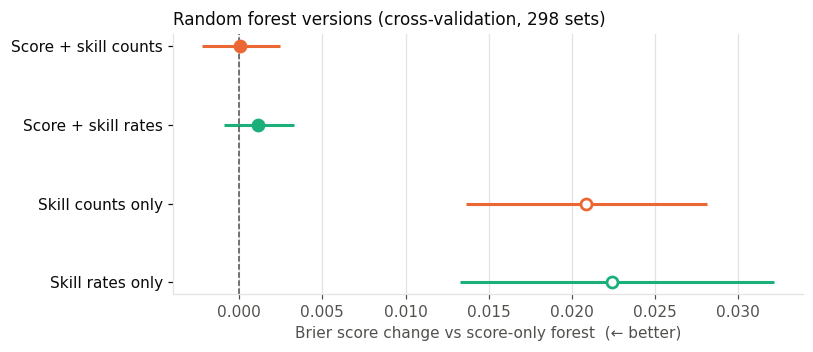

In [4]:
shown = overall.drop(index=REFERENCE).loc[[v for v in VERSIONS if v != REFERENCE]][::-1]
y = np.arange(len(shown))

fig, ax = plt.subplots(figsize=(7.5, 0.5 * len(shown) + 1.3))
for yi, (feature_set, row) in zip(y, shown.iterrows()):
    colour = VERSIONS[feature_set][1]
    ax.hlines(yi, row["diff_low"], row["diff_high"], color=colour, linewidth=2)
    ax.scatter(row["diff"], yi, s=52, zorder=3, **marker_style(feature_set))
ax.axvline(0, color=MUTED, linestyle="--", linewidth=1)
ax.set_yticks(y, [VERSIONS[v][0] for v in shown.index])
ax.grid(axis="y", visible=False)
ax.set_xlabel("Brier score change vs score-only forest  (← better)")
ax.set_title(f"Random forest versions (cross-validation, {int(overall['sets'].iloc[0])} sets)",
             loc="left", fontsize=11, color=INK)
plt.tight_layout()

## 2. Does the margin change which inputs work best?

Rallies are grouped by the **current** margin, |CU score − opponent score|,
which is known at prediction time. At a small margin the score inputs say
little, so this is where skills alone could compete with, or add to, the
score.

Left: raw Brier for every version (and the base rate), which shows how hard
each margin is. Right: each version's paired change vs the score-only forest
within that margin.

In [5]:
BUCKETS = ["0", "1", "2", "3-4", "5-7", "8+"]
pred["margin"] = pd.cut(pred["score_difference"].abs(), [-1, 0, 1, 2, 4, 7, np.inf],
                        labels=BUCKETS)
by_margin = pd.concat({b: score(pred[pred["margin"] == b]) for b in BUCKETS},
                      names=["margin", "feature_set"]).reset_index()

# Base rate for reference: the training share of sets CU won, scored the same way.
base = pd.read_csv("predictions/base_rate__none.csv")
base = base[base["split"] == "cv"].merge(meta, on=KEYS)
base["brier"] = (base["win_probability"] - base["home_set_win"]) ** 2
base["margin"] = pd.cut(base["score_difference"].abs(), [-1, 0, 1, 2, 4, 7, np.inf],
                        labels=BUCKETS)
base_by_margin = (base.groupby(["margin", "match_id", "set_number"], observed=True)["brier"]
                  .mean().groupby("margin", observed=True).mean())

table = by_margin.pivot(index="feature_set", columns="margin", values="brier")[BUCKETS]
table.loc["base rate"] = base_by_margin[BUCKETS]
table.loc[[*VERSIONS, "base rate"]].round(4)

margin,0,1,2,3-4,5-7,8+
feature_set,,,,,,
score,0.2521,0.2223,0.1881,0.1393,0.0909,0.0174
score_skills,0.2562,0.2188,0.1880,0.1411,0.0919,0.0179
score_rates,0.2547,0.2211,0.1880,0.1397,0.0921,0.0196
skills,0.2609,0.2468,0.2137,0.1626,0.1058,0.0289
rates,0.2703,0.2487,0.2153,0.1651,0.1155,0.0402
base rate,0.2531,0.2521,0.2521,0.2517,0.2521,0.2557


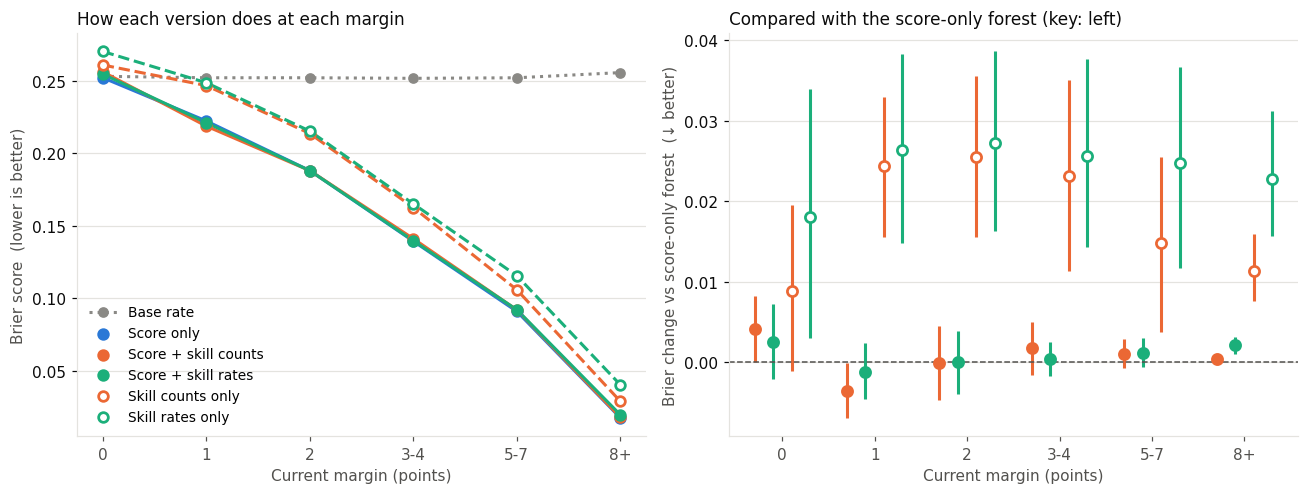

In [6]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.6))
x = np.arange(len(BUCKETS))

left.plot(x, base_by_margin[BUCKETS], color="#8a8985", linestyle=":", linewidth=2,
          marker="o", markersize=6, label="Base rate")
for feature_set, (name, colour, with_score) in VERSIONS.items():
    b = by_margin[by_margin["feature_set"] == feature_set].set_index("margin").loc[BUCKETS]
    left.plot(x, b["brier"], color=colour, linewidth=2,
              linestyle="-" if with_score else "--")
    left.scatter(x, b["brier"], s=40, zorder=3, label=name, **marker_style(feature_set))
left.set_xticks(x, BUCKETS)
left.set_xlabel("Current margin (points)")
left.set_ylabel("Brier score  (lower is better)")
left.set_title("How each version does at each margin", loc="left", fontsize=11, color=INK)
left.legend(frameon=False, fontsize=9)
left.grid(axis="x", visible=False)

others = [v for v in VERSIONS if v != REFERENCE]
offsets = np.linspace(-0.3, 0.3, len(others))
for feature_set, dx in zip(others, offsets):
    g = by_margin[by_margin["feature_set"] == feature_set].set_index("margin").loc[BUCKETS]
    right.vlines(x + dx, g["diff_low"], g["diff_high"], color=VERSIONS[feature_set][1],
                 linewidth=2)
    right.scatter(x + dx, g["diff"], s=44, zorder=3, label=VERSIONS[feature_set][0],
                  **marker_style(feature_set))
right.axhline(0, color=MUTED, linestyle="--", linewidth=1)
right.set_xticks(x, BUCKETS)
right.set_xlabel("Current margin (points)")
right.set_ylabel("Brier change vs score-only forest  (↓ better)")
right.set_title("Compared with the score-only forest (key: left)", loc="left", fontsize=11, color=INK)
# Same colours and markers as the left panel, whose legend serves both.
right.grid(axis="x", visible=False)
plt.tight_layout()